In [2]:
import numpy as np
import skimage.io
import skimage.color
import skimage.filters
import skimage.transform
from skimage import img_as_ubyte
import matplotlib.pyplot as plt
import constants
import IPython.display as d
import json
import os
import time
import torch
import torchvision
from torchvision import transforms, utils, datasets
from torch.utils.data import Dataset, DataLoader
from torch.autograd import Variable
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import shutil
import pandas as pd
from sklearn import metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torchvision import models
from pytorch_model_summary import summary

Data inladen

In [115]:
transform = transforms.Compose([transforms.ToTensor()])
train_data = datasets.ImageFolder("./data/data_512/images_64_base/train", transform=transform)
test_data = datasets.ImageFolder("./data/data_512/images_64_base/test", transform=transform)

batch_size = 128
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size,shuffle=True)
print("Size of training set: ", len(train_loader)*batch_size)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size,shuffle=True)
print("Size of test set: ", len(test_loader)*batch_size)

aantal_pos = len(os.listdir("./data/data_512/images_64_base/train/positive"))
aantal_neg = len(os.listdir("./data/data_512/images_64_base/train/negative"))
samples = [aantal_pos, aantal_neg]
weights = [1 - (x / sum(samples)) for x in samples]
weights

Size of training set:  30592
Size of test set:  10240


[0.996590611067401, 0.003409388932599011]

Trainingsklasse en functies

In [3]:
class Filter(nn.Module):
    def __init__(self):
        super(Filter, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.classifier = nn.Sequential(
            nn.Linear(2048, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

model = Filter()
model.cuda()
loss_fun = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(),lr = 0.001)

def save_model():
    path = "./trained_models/base_realistic_data.pth"
    torch.save(model.state_dict(), path)

def calculate_weights(labels):
    weights = [0.996590611067401 if label == 1.0 else 0.003409388932599011 for label in labels]
    return torch.FloatTensor(weights)

def calculate_stats(gt, predicted):
    tp = tn = fp = fn = 0
    for i in range(len(gt)):
        if gt[i] == 0 and predicted[i] == 0:
            tn += 1
        elif gt[i] == 0 and predicted[i] == 1:
            fp += 1
        elif gt[i] == 1 and predicted[i] == 0:
            fn += 1
        elif gt[i] == 1 and predicted[i] == 1:
            tp += 1
    return tp, tn, fp, fn

def calculate_metrics(tp, tn, fp, fn):
    a = (tp + tn) / (tp + tn + fp + fn)
    p = tp / (tp + fp)
    r = tp / (tp + fn)
    return a, p, r

def test_accuracy():
    model.eval()
    true = []
    pred = []
    total = 0.0
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    with torch.no_grad():
        for (images, labels) in test_loader:
            images = Variable(images.to(device))
            labels = Variable(labels.to(device))
            labels = labels.unsqueeze(1).float()
            outputs = model(images)
            test_loss = loss_fun(outputs, labels)
            total += labels.size(0)
            #print(str(outputs))
            outputs = outputs.detach().cpu().numpy()
            for i in range(len(outputs)):
                if outputs[i] > 0.5:
                    outputs[i] = 1
                else:
                    outputs[i] = 0
            #print(outputs)
            labels = labels.detach().cpu().numpy()
            true.extend(labels)
            pred.extend(outputs)
    a = metrics.accuracy_score(true, pred)
    p = metrics.precision_score(true, pred)
    r = metrics.recall_score(true, pred)
    cm = confusion_matrix(true, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot()
    plt.show()
    return a, p, r, test_loss

def train(epochs):
    best_accuracy = 0.0
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    print("DEVICE:",device)
    model.to(device)
    p_list = []
    r_list = []
    a_list = []
    train_losses = []
    test_losses = []
    for epoch in range(epochs):  # loop over the dataset multiple times
        for i, (images, labels) in enumerate(train_loader, 0):
            images = Variable(images.to(device))
            labels = Variable(labels.to(device))
            optimizer.zero_grad()
            # predictions
            outputs = model(images)
            # bereken loss
            labels = labels.unsqueeze(1).float()
            new_weights = calculate_weights(labels).unsqueeze(1).float().to(device)
            loss_fun = nn.BCELoss(weight=new_weights)
            loss = loss_fun(outputs, labels)
            # loss backpropagation
            loss.backward()
            # weights aanpassen
            optimizer.step()

        # test de weights van deze epoch op de testdata
        acc, pr, rec, test_loss = test_accuracy()
        p_list.append(pr)
        r_list.append(rec)
        a_list.append(acc)
        train_losses.append(loss)
        test_losses.append(test_loss)
        print("Epoch ", epoch+1, ':\tAccuracy: %f %%, Precision: %f %%, Recall: %f %%, training loss: %f, test loss: %f' % (acc*100, pr*100, rec*100, loss, test_loss))
        
        # sla beste model op
        if acc > best_accuracy:
            save_model()
            best_accuracy = acc
    return p_list, r_list, a_list, train_losses, test_losses

In [4]:
print(summary(Filter(), torch.zeros((1, 3, 64, 64)), show_input=True))

-----------------------------------------------------------------------
      Layer (type)         Input Shape         Param #     Tr. Param #
          Conv2d-1      [1, 3, 64, 64]             224             224
            ReLU-2      [1, 8, 64, 64]               0               0
       MaxPool2d-3      [1, 8, 64, 64]               0               0
          Conv2d-4      [1, 8, 32, 32]           1,168           1,168
            ReLU-5     [1, 16, 32, 32]               0               0
       MaxPool2d-6     [1, 16, 32, 32]               0               0
          Conv2d-7     [1, 16, 16, 16]           4,640           4,640
            ReLU-8     [1, 32, 16, 16]               0               0
       MaxPool2d-9     [1, 32, 16, 16]               0               0
         Linear-10           [1, 2048]         131,136         131,136
           ReLU-11             [1, 64]               0               0
         Linear-12             [1, 64]              65              65
     

In [ ]:
p, r, a, train_loss, test_loss = train(50)
print("finished training...")
test_accuracy()

Evaluation metrics

In [ ]:
plt.plot(train_loss, label='Training loss')
plt.plot(test_loss, label='Validation loss')
plt.legend()
plt.show()
plt.plot(a, label='Accuracy')
plt.plot(p, label='Precision')
plt.plot(r, label='Recall')
plt.legend()
plt.show() 

In [ ]:

def get_ground_truth(filename, count, width, x_length):
    gt = np.zeros(count)
    f = open(filename, "r")
    for line in f:
        arr = line.split("\t")
        x_center = float(arr[1])
        y_center = float(arr[2])
        index = int(x_center//width + (x_length//width) * (y_center//width))
        try:
            gt[index] = 1
        except:
            continue
    return gt

def split_image(img, size):
    data = []
    y = 0
    while(y < constants.Y_END - size):
        x = 0
        while(x < constants.X_END - size):
            x_end = x+size if x+size < constants.X_END else constants.X_END
            y_end = y+size if y+size < constants.Y_END else constants.Y_END
            data.append(img[y:y_end,x:x_end])
            x += size - constants.OVERLAP
        y += size - constants.OVERLAP
    return data

model = Filter()
model.cuda()
model.load_state_dict(torch.load(f"./trained_models/base_moredata.pth"))
model.eval()
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
dir_images = "./data/images_full/"
dir_labels = "./data/labels_full/"
gt_all = []
pred_all = []
img_all = []
teller = 0
for filename in os.listdir(os.path.join(os.getcwd(), dir_images)):
    teller += 1
    print(teller)
    filename = filename.split(".")[0]
    gt = get_ground_truth(f"{dir_labels}/{filename}.txt", 10168, 64, 7952)
    gt_all.extend(gt)
    img = skimage.io.imread(f"{dir_images}/{filename}.JPG")
    data = split_image(img, 64)
    img_all.extend(data)
    transform = transforms.Compose([transforms.ToTensor()])
    input = torch.cat([transform(np.array(i)).float().unsqueeze(0).to(device) for i in data], 0)
    output = model(input)
    output = output.to(device).data.cpu().numpy()
    pred_all.extend(output)



threshold: [0.9832755], p: [0.51294964], r: [0.76134544], f1: [0.61293789]


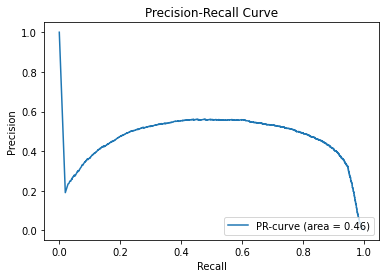

In [4]:
precision, recall, threshold = metrics.precision_recall_curve(gt_all, pred_all)
f1_scores = 2*recall*precision/(recall+precision)
max = np.max(f1_scores)
index = np.where(f1_scores == max)
print(f"threshold: {threshold[index]}, p: {precision[index]}, r: {recall[index]}, f1: {f1_scores[index]}")
ap = metrics.average_precision_score(gt_all, pred_all)
fig, ax = plt.subplots()
ax.plot(recall, precision, label="PR-curve (area = %0.2f)" % ap)
ax.set_title('Precision-Recall Curve')
ax.set_ylabel('Precision')
ax.set_xlabel('Recall')
ax.legend(loc="lower right")
plt.savefig("mygraphbase.png")

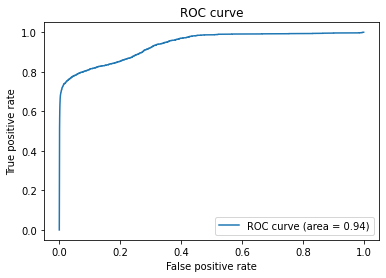

In [124]:
fpr, tpr, threshold = metrics.roc_curve(gt_all, pred_all)
roc_auc = metrics.auc(fpr, tpr)
final_all = [1 if i > 0.5 else 0 for i in pred_all]
fig, ax = plt.subplots()
ax.plot(fpr, tpr, label="ROC curve (area = %0.2f)" % roc_auc)
ax.set_title('ROC curve')
ax.set_ylabel('True positive rate')
ax.set_xlabel('False positive rate')
ax.legend(loc="lower right")
plt.show()

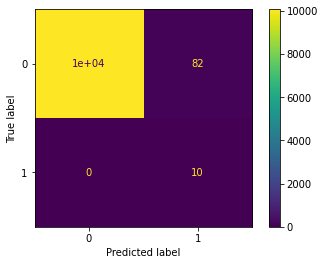

In [95]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
t = 0.5
final_all = [1 if i > t else 0 for i in pred_all]
cm = confusion_matrix(gt_all, final_all)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()